# 02 – Flood extent with MNDWI
Map open water on the Landsat 8 images before, during and after the flood with the MNDWI,
choose the threshold, and compute the flooded area.

**Flood** = water during the flood, but not water before, and not permanent water (JRC).

## Why MNDWI?
The **Modified Normalized Difference Water Index** (Xu, 2006) compares green and shortwave-infrared (SWIR) reflectance:

$$\text{MNDWI} = \frac{\text{Green} - \text{SWIR1}}{\text{Green} + \text{SWIR1}} \qquad \text{(Landsat 8: B3 and B6)}$$

Water reflects some green light but absorbs almost all SWIR, so water has MNDWI > 0. Soil, vegetation and buildings
reflect more SWIR than green, so they have MNDWI < 0.

Why this index:
- Compared with the older NDWI (green vs near-infrared, McFeeters 1996), MNDWI separates water better from built-up areas and bare soil. In April the fields in the valley are bare.
- It needs only two bands and one threshold, so it is simple and easy to reproduce.
- Landsat 8 had a nearly cloud-free image on 22 Apr 2019 at 30 m resolution.

In [1]:
import ee
import matplotlib.pyplot as plt
import pandas as pd

import common as c
import config as cfg

c.init()
cfg.FIGURES.mkdir(parents=True, exist_ok=True)

aoi = c.study_area()
total_km2 = c.geometry_km2(aoi)
print(f"Study area: {total_km2:.0f} km²")

Study area: 4238 km²


## Landsat 8 images and MNDWI
Clouds, cloud shadows and snow are masked with the `QA_PIXEL` band.
We can't use an NDSI snow threshold: for Landsat, NDSI and MNDWI are the same formula (green vs SWIR1),
so snow and water look the same in both. The QA snow flag also uses other bands and temperature.

In [2]:
dates = {"before": cfg.L8_BEFORE, "during": cfg.L8_DURING, "after": cfg.L8_AFTER}
images = {name: c.landsat8_image(day, aoi) for name, day in dates.items()}
mndwi = {name: c.mndwi(image) for name, image in images.items()}

for name, image in mndwi.items():
    masked_km2 = c.area_km2(image.mask().Not(), aoi)  # mask() is 0 where a pixel is masked
    print(f"{name:7s} {dates[name]}: {100 * masked_km2 / total_km2:.1f} % masked (cloud/shadow/snow)")

before  2018-09-10: 0.0 % masked (cloud/shadow/snow)


during  2019-04-22: 0.8 % masked (cloud/shadow/snow)


after   2019-08-28: 0.0 % masked (cloud/shadow/snow)


## Threshold
Water has a high MNDWI and land a low one. We compare two thresholds:
- **0**: the standard value from the original MNDWI paper (Xu, 2006).
- **Otsu**: picks the value that best splits the histogram into two groups. This only works when the image
  has enough water to form a second peak, so we compute it on the flood image.

Otsu threshold on the flood image: 0.059


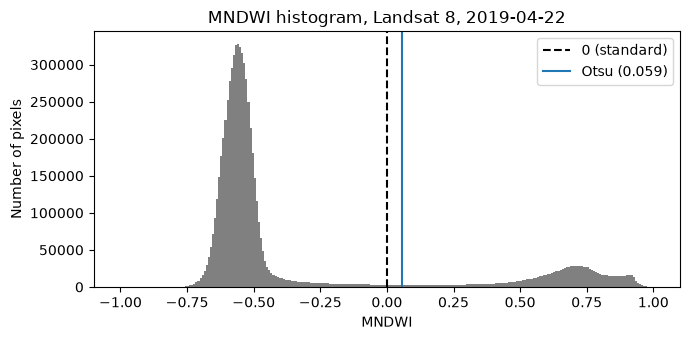

In [3]:
values, counts = c.histogram(mndwi["during"], aoi)
otsu_threshold = c.otsu(values, counts)
print(f"Otsu threshold on the flood image: {otsu_threshold:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(values, counts, width=values[1] - values[0], color="grey")
ax.axvline(0, color="black", linestyle="--", label="0 (standard)")
ax.axvline(otsu_threshold, color="tab:blue", label=f"Otsu ({otsu_threshold:.3f})")
ax.set_xlabel("MNDWI")
ax.set_ylabel("Number of pixels")
ax.set_title(f"MNDWI histogram, Landsat 8, {cfg.L8_DURING}")
ax.legend()
fig.tight_layout()
fig.savefig(cfg.FIGURES / "mndwi_histogram.png", dpi=200)

In [4]:
for threshold in [0.0, otsu_threshold]:
    water_km2 = c.area_km2(mndwi["during"].gt(threshold), aoi)
    print(f"Threshold {threshold:.3f}: {water_km2:.0f} km² water on {cfg.L8_DURING}")

Threshold 0.000: 763 km² water on 2019-04-22


Threshold 0.059: 750 km² water on 2019-04-22


Both thresholds give almost the same water area, so the result does not depend much on the exact choice.
We use `cfg.MNDWI_THRESHOLD = 0`.

## Water and flood masks

In [5]:
water = {name: image.gt(cfg.MNDWI_THRESHOLD) for name, image in mndwi.items()}
# Flood = water during AND NOT water before AND NOT permanent water (see c.optical_flood)
flood = c.optical_flood(cfg.L8_DURING, aoi)

rows = []
for name in water:
    rows.append({"layer": f"water {name}", "date": dates[name], "area_km2": c.area_km2(water[name], aoi)})
rows.append({"layer": "flood", "date": cfg.L8_DURING, "area_km2": c.area_km2(flood, aoi)})
rows.append({"layer": "permanent water (JRC)", "date": "", "area_km2": c.area_km2(c.permanent_water(), aoi)})

areas = pd.DataFrame(rows).round(1)
areas.to_csv(cfg.TABLES / "mndwi_areas.csv", index=False)
areas

,layer,date,area_km2
0,water before,2018-09-10,22.1
1,water during,2019-04-22,763.2
2,water after,2019-08-28,24.4
3,flood,2019-04-22,742.3
4,permanent water (JRC),,9.1


## Map: check the mask by eye
Turn the layers on and off (layer icon, top right):
- **True colour** (red, green, blue) looks like a photo. Floodwater is brown or dark grey from mud, and hard to tell apart from wet dark soil.
- **False colour** (SWIR1, NIR, red): water absorbs SWIR and NIR, so it is **black or dark blue**. Bare soil is pink/brown, vegetation green.
- Compare 22 Apr with 10 Sep 2018: the dark areas that are new on 22 Apr should be covered by the cyan flood mask.

In [6]:
true_color = {"bands": ["SR_B4", "SR_B3", "SR_B2"], "min": 0, "max": 0.25}
false_color = {"bands": ["SR_B6", "SR_B5", "SR_B4"], "min": 0, "max": 0.35}

m = c.Map(center=(48.5, -97.1), zoom=9)
for name in ["before", "during"]:
    date = dates[name]
    m.addLayer(images[name], true_color, f"True colour {date}", False)
    m.addLayer(images[name], false_color, f"False colour {date}", name == "during")
m.addLayer(c.permanent_water().selfMask().clip(aoi), {"palette": ["navy"]}, "Permanent water (JRC)")
m.addLayer(flood.selfMask(), {"palette": ["cyan"]}, "Flood (MNDWI)")
m.addLayer(ee.FeatureCollection(aoi), {"color": "red"}, "Study area", False)
m

Map(center=[48.5, -97.1], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## Static figure for the report

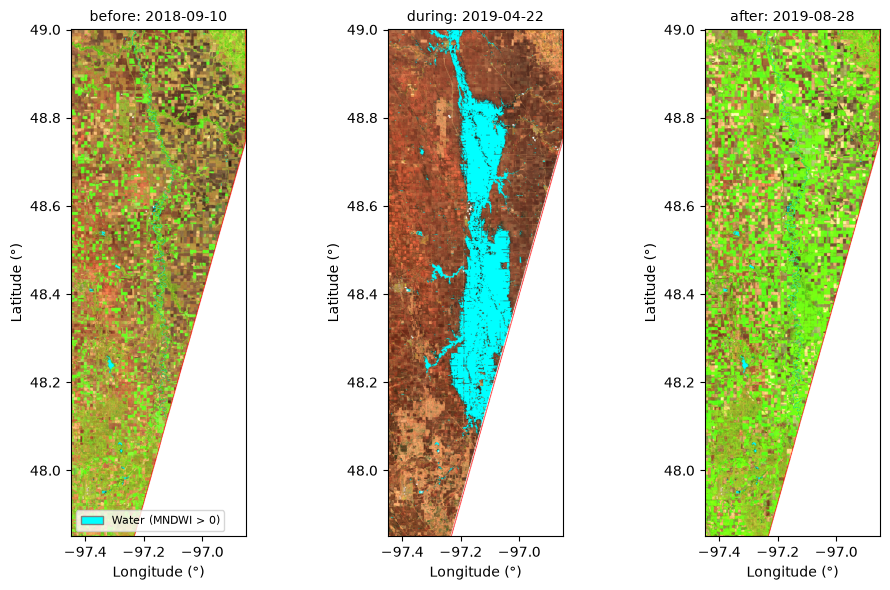

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10, 6))
for ax, (name, day) in zip(axes, dates.items()):
    layer = (
        images[name].visualize(**false_color)
        .blend(water[name].selfMask().visualize(palette=["00ffff"]))
        .blend(c.outline(aoi))
    )
    c.plot_map(ax, layer, aoi, f"{name}: {day}")
axes[0].legend(handles=c.legend_patches({"Water (MNDWI > 0)": "#00ffff"}), loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(cfg.FIGURES / "mndwi_before_during_after.png", dpi=200)

## Notes
- **Flooded area on 22 Apr 2019: about 740 km²**, which is 17 % of the 4,240 km² study area (MNDWI > 0, minus water on 10 Sep 2018 and JRC permanent water).
- Normal water: about 22–24 km² before and after, so by late August the water was back to normal.
- Threshold: the histogram has two clear peaks (land around −0.55, water around 0.7). Otsu gives 0.059, and the water area differs by only 1.7 % from threshold 0 (763 vs 750 km²). We use 0.
- Masked (cloud/shadow/snow): below 1 % on all three dates.
- Timing: the Oslo gauge read 37.5 ft on 22 Apr (major flood stage 36 ft, record 38.4 ft; NWS hydrograph in the CIMSS blog), so the image is close to the local peak. Fargo, far upstream, had peaked two weeks earlier.
- The flood continues east of the Landsat image edge (see the figure), so 742 km² is a lower bound.
- Limitations: Flooded vegetation and water under the remaining river ice are missed. Very wet fields and shallow ponding can count as water. 30 m pixels miss narrow water along roads and ditches.